# **Heart Health Information Assistant**

In [ ]:
!pip install nltk scikit-learn pandas numpy matplotlib seaborn gradio

In [ ]:
import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gradio as gr

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("Libraries imported successfully!")

Libraries imported successfully!


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [ ]:
data = {

    "query": [

        # 1. SYMPTOMS (15)

        "What are the symptoms of heart disease?",
        "How can I identify a heart attack?",
        "Why do I experience chest discomfort?",
        "What are the signs of an irregular heartbeat?",
        "Can heart problems cause shortness of breath?",
        "Why am I experiencing heart palpitations?",
        "What are common symptoms of cardiovascular disease?",
        "Can unusual fatigue indicate heart disease?",
        "What does chest pressure indicate?",
        "Why do I feel dizzy when my heart beats fast?",
        "What are the early warning signs of heart problems?",
        "Can a heart condition cause excessive sweating?",
        "Why do I feel pain spreading to my left arm?",
        "What happens when someone has an irregular pulse?",
        "How do heart disease symptoms appear in adults?",

        # 2. PREVENTION (15)

        "How can I keep my heart healthy?",
        "What exercises are good for heart health?",
        "How can I prevent cardiovascular disease?",
        "What foods should I eat for a healthy heart?",
        "How does walking improve heart health?",
        "How can I reduce my risk of heart problems?",
        "Is quitting smoking beneficial for the heart?",
        "How important is sleep for cardiovascular health?",
        "What lifestyle changes prevent heart disease?",
        "How can I maintain a healthy cardiovascular system?",
        "Does daily exercise protect the heart?",
        "What diet is recommended for a healthy heart?",
        "How can I improve my heart fitness naturally?",
        "What habits help prevent heart attacks?",
        "How does reducing salt intake help the heart?",

        # 3. RISK FACTORS (15)

        "Does smoking increase the risk of heart disease?",
        "Can high blood pressure damage the heart?",
        "Does diabetes increase cardiovascular risk?",
        "How does obesity affect heart health?",
        "Can high cholesterol cause heart disease?",
        "Is family history a risk factor for heart disease?",
        "Does stress affect cardiovascular health?",
        "Can physical inactivity increase heart disease risk?",
        "Does excessive salt increase blood pressure?",
        "How does age influence cardiovascular risk?",
        "Can unhealthy eating cause heart problems?",
        "Is alcohol consumption a heart disease risk factor?",
        "Why is hypertension dangerous for the heart?",
        "Can diabetes damage blood vessels?",
        "What factors increase the chances of a heart attack?",


        # 4. DIAGNOSIS (15)

        "What is an ECG test?",
        "How is heart disease diagnosed?",
        "What does an echocardiogram detect?",
        "Why do doctors perform a cardiac stress test?",
        "What is coronary angiography?",
        "Can a blood test identify heart problems?",
        "What is the purpose of a cholesterol test?",
        "How does an ECG measure electrical heart activity?",
        "What is an echocardiography examination?",
        "Which tests check heart function?",
        "How do doctors examine blocked arteries?",
        "What is a cardiac MRI scan?",
        "Why is a treadmill test performed?",
        "What does an abnormal ECG indicate?",
        "How can doctors evaluate cardiovascular health?",

        # 5. TREATMENT (15)

        "How is heart disease treated?",
        "What medicines are used for high blood pressure?",
        "Can heart disease be managed with medication?",
        "What is angioplasty?",
        "When is bypass surgery required?",
        "How do doctors treat irregular heartbeats?",
        "What treatment is available for blocked arteries?",
        "Can lifestyle changes help manage heart disease?",
        "What treatments are available for coronary artery disease?",
        "How is hypertension managed medically?",
        "What is the purpose of a pacemaker?",
        "How do doctors manage heart failure?",
        "What happens during heart bypass surgery?",
        "Are medicines available to lower cholesterol?",
        "What medical procedures treat narrowed arteries?",

        # 6. GENERAL HEART HEALTH (15)

        "What is the function of the human heart?",
        "How many chambers does the heart have?",
        "How does blood circulate through the body?",
        "What is cardiovascular health?",
        "Why is the heart important?",
        "What are arteries and veins?",
        "What is a normal resting heart rate?",
        "How does the heart pump blood?",
        "Where is the human heart located?",
        "What is the role of heart valves?",
        "How does oxygen reach different body organs?",
        "What is the circulatory system?",
        "What is the difference between arteries and veins?",
        "How much blood does the heart pump?",
        "What are the four chambers of the heart?"
    ],

    "intent": (
        ["symptoms"] * 15 +
        ["prevention"] * 15 +
        ["risk_factors"] * 15 +
        ["diagnosis"] * 15 +
        ["treatment"] * 15 +
        ["heart_health"] * 15
    )
}

df = pd.DataFrame(data)

print("Total queries:", len(df))

print("\nIntent distribution:")
print(df["intent"].value_counts())

print("\nDataset shape:", df.shape)

Total queries: 90

Intent distribution:
intent
symptoms        15
prevention      15
risk_factors    15
diagnosis       15
treatment       15
heart_health    15
Name: count, dtype: int64

Dataset shape: (90, 2)


In [ ]:
lemmatizer = WordNetLemmatizer()

stop_words = set(stopwords.words('english'))

# Preserve negation words
stop_words -= {"no", "not", "nor", "never"}


def preprocess(text):

    # Lowercase conversion
    text = text.lower()

    # Remove special characters
    text = re.sub(r'[^a-z\s]', '', text)

    # Tokenization
    tokens = word_tokenize(text)

    # Stopword removal
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return " ".join(tokens)


df["processed_query"] = df["query"].apply(preprocess)

print(df[["query", "processed_query", "intent"]].head(10))

                                               query  \
0            What are the symptoms of heart disease?   
1                 How can I identify a heart attack?   
2              Why do I experience chest discomfort?   
3      What are the signs of an irregular heartbeat?   
4      Can heart problems cause shortness of breath?   
5          Why am I experiencing heart palpitations?   
6  What are common symptoms of cardiovascular dis...   
7        Can unusual fatigue indicate heart disease?   
8                 What does chest pressure indicate?   
9      Why do I feel dizzy when my heart beats fast?   

                          processed_query    intent  
0                   symptom heart disease  symptoms  
1                   identify heart attack  symptoms  
2             experience chest discomfort  symptoms  
3                sign irregular heartbeat  symptoms  
4    heart problem cause shortness breath  symptoms  
5          experiencing heart palpitation  symptoms  
6   c

In [ ]:
X = df["processed_query"]
y = df["intent"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train_text))
print("Testing samples:", len(X_test_text))

# Improved TF-IDF
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True,
    strip_accents="unicode"
)

X_train = vectorizer.fit_transform(X_train_text)

X_test = vectorizer.transform(X_test_text)

print("\nTF-IDF training shape:", X_train.shape)
print("TF-IDF testing shape:", X_test.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

Training samples: 67
Testing samples: 23

TF-IDF training shape: (67, 304)
TF-IDF testing shape: (23, 304)
Vocabulary size: 304


In [ ]:
model = LogisticRegression(
    C=5.0,
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
y_pred = model.predict(X_test)

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print("\nMODEL EVALUATION RESULTS")
print("------------------------")

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\nCLASSIFICATION REPORT")
print("---------------------")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)


MODEL EVALUATION RESULTS
------------------------
Accuracy : 0.6087
Precision: 0.6551
Recall   : 0.6087
F1 Score : 0.6166

CLASSIFICATION REPORT
---------------------
              precision    recall  f1-score   support

   diagnosis       1.00      0.67      0.80         3
heart_health       0.67      0.50      0.57         4
  prevention       0.25      0.25      0.25         4
risk_factors       1.00      0.75      0.86         4
    symptoms       0.60      0.75      0.67         4
   treatment       0.50      0.75      0.60         4

    accuracy                           0.61        23
   macro avg       0.67      0.61      0.62        23
weighted avg       0.66      0.61      0.62        23



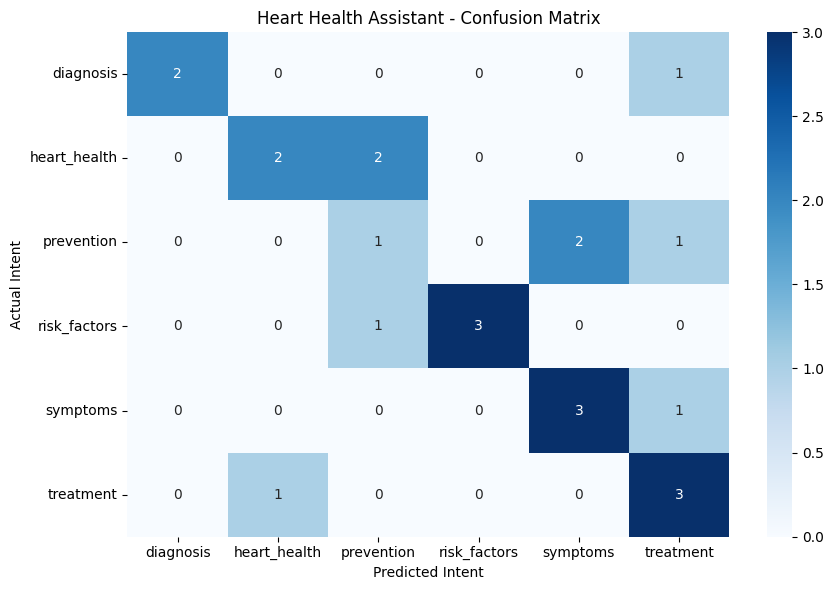

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")

plt.title("Heart Health Assistant - Confusion Matrix")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.pipeline import Pipeline

cv_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=1,
        sublinear_tf=True
    )),

    ("classifier", LogisticRegression(
        C=5.0,
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

cv_scores = cross_val_score(
    cv_pipeline,
    X,
    y,
    cv=5,
    scoring="accuracy"
)

print("5-Fold Cross Validation Scores:", cv_scores)

print(
    "Average Cross Validation Accuracy:",
    round(cv_scores.mean(), 4)
)

print(
    "Standard Deviation:",
    round(cv_scores.std(), 4)
)

5-Fold Cross Validation Scores: [0.66666667 0.5        0.55555556 0.72222222 0.72222222]
Average Cross Validation Accuracy: 0.6333
Standard Deviation: 0.0903


In [ ]:
knowledge_base = {

    "symptoms": """
    Common symptoms associated with heart conditions include
    chest discomfort, shortness of breath, unusual fatigue,
    dizziness, palpitations and irregular heartbeat.

    Heart attack warning signs can include chest pressure,
    discomfort spreading to the arm, jaw or back, sweating,
    nausea and breathlessness.

    Symptoms vary between individuals. New or concerning
    symptoms should be assessed by a healthcare professional.
    """,

    "prevention": """
    Heart health can be supported through regular physical
    activity, a balanced diet, maintaining a healthy weight,
    avoiding tobacco and getting sufficient sleep.

    Regular checkups can help monitor blood pressure,
    blood sugar and cholesterol levels.
    """,

    "risk_factors": """
    Cardiovascular risk factors include high blood pressure,
    high cholesterol, diabetes, smoking, obesity, physical
    inactivity, unhealthy diet, family history and age.

    Some risk factors can be reduced through lifestyle
    modifications and appropriate medical care.
    """,

    "diagnosis": """
    Doctors use different tests to evaluate heart health.

    ECG records the electrical activity of the heart.
    Echocardiography uses ultrasound to examine heart structure
    and pumping function.
    Stress testing evaluates heart activity during exercise.
    Blood tests may measure cholesterol and cardiac biomarkers.

    A healthcare professional decides which tests are appropriate.
    """,

    "treatment": """
    Heart disease treatment depends on its type and severity.

    Treatment may involve lifestyle changes, prescribed
    medicines, angioplasty or bypass surgery.

    Medication should only be taken according to the
    instructions of a qualified healthcare professional.

    Never start, stop or change prescribed medicines
    without medical advice.
    """,

    "heart_health": """
    The human heart is a muscular organ that pumps blood
    throughout the body.

    It has four chambers: two atria and two ventricles.

    Arteries generally carry blood away from the heart,
    while veins generally carry blood toward the heart.

    The circulatory system transports oxygen and nutrients
    throughout the body.
    """
}

print("Knowledge base created successfully!")

Knowledge base created successfully!


In [ ]:
# Heart health domain vocabulary

domain_keywords = {
    "heart", "cardiac", "cardiovascular",
    "blood", "pressure", "cholesterol",
    "attack", "artery", "arteries",
    "vein", "veins", "ecg", "ekg",
    "pulse", "heartbeat", "hypertension",
    "angioplasty", "bypass", "cardiology",
    "palpitation", "palpitations", "chest",
    "coronary", "circulation", "circulatory",
    "atrial", "ventricular", "cardiomyopathy",
    "valve", "cardiac", "myocardial",
    "treadmill", "echocardiogram", "echocardiography",
    "exercise", "fitness", "smoking",
    "diabetes", "obesity", "fatigue",
    "dizziness", "arrhythmia", "systolic",
    "diastolic", "arterial", "resting"
}


# Emergency patterns
emergency_patterns = [
    r'\bsevere chest pain\b',
    r'\bchest pain\b',
    r'\bheart attack\b',
    r'\bcardiac arrest\b',
    r'\bcannot breathe\b',
    r'\bcan.t breathe\b',
    r'\bsevere shortness of breath\b',
    r'\bunconscious\b',
    r'\bnot breathing\b',
    r'\bsudden collapse\b',
    r'\bpassed out\b'
]


def is_emergency(query):

    query = query.lower()

    return any(
        re.search(pattern, query)
        for pattern in emergency_patterns
    )


def is_heart_health_query(query):

    words = set(
        re.findall(r'\b[a-z]+\b', query.lower())
    )

    return bool(words.intersection(domain_keywords))


def reasoning_engine(query):

    # Rule 1: Empty input
    if not query or not query.strip():

        return "Please enter a healthcare-related question."

    # Rule 2: Emergency escalation
    if is_emergency(query):

        return """
        EMERGENCY ALERT!

        Your query mentions a potentially life-threatening symptom.

        If you or someone nearby is experiencing severe chest pain,
        difficulty breathing, collapse or suspected heart attack:

        1. Call emergency services immediately.
        2. In India, call 112 for emergency assistance.
        3. Do not drive yourself to the hospital.
        4. Follow the emergency operator's instructions.

        Do not wait for this assistant to assess your symptoms.

        This assistant cannot diagnose or rule out an emergency.
        """

    # Rule 3: Unsupported query
    if not is_heart_health_query(query):

        return """
        I am sorry, but I currently support heart-health-related
        information only.

        You can ask me about:

        - Heart disease symptoms
        - Heart disease prevention
        - Cardiovascular risk factors
        - Heart diagnostic tests
        - Heart disease treatment
        - General heart health
        """

    # Rule 4: Preprocessing
    processed = preprocess(query)

    # Rule 5: TF-IDF conversion
    query_vector = vectorizer.transform([processed])

    # Rule 6: Intent classification
    probabilities = model.predict_proba(query_vector)[0]

    predicted_index = np.argmax(probabilities)

    predicted_intent = model.classes_[predicted_index]

    confidence = probabilities[predicted_index]

    # Rule 7: Low confidence
    if confidence < 0.2:

        return f"""
        I am not sufficiently confident about understanding
        your question.

        Confidence: {confidence:.2f}

        Please rephrase your question using heart-health-related
        terms such as symptoms, prevention, diagnosis or treatment.
        """

    # Rule 8: Knowledge retrieval
    if predicted_intent in knowledge_base:

        response = knowledge_base[predicted_intent]

        return f"""
        Predicted Intent: {predicted_intent}

        Confidence: {confidence:.2f}

        Healthcare Information:

        {response}

        Disclaimer:
        This information is for educational purposes only.
        It is not a substitute for professional medical advice.
        """

    # Rule 9: Fallback
    return """
    Sorry, I could not find suitable information.
    Please ask another heart-health-related question.
    """


print("Improved reasoning engine created successfully!")

Improved reasoning engine created successfully!


In [ ]:
def heart_health_assistant(user_query):

    return reasoning_engine(user_query)


query = "What are the symptoms of heart disease?"

print("USER:", query)

print("\nASSISTANT:")

print(heart_health_assistant(query))

USER: What are the symptoms of heart disease?

ASSISTANT:

        Predicted Intent: symptoms

        Confidence: 0.26

        Healthcare Information:

        
    Common symptoms associated with heart conditions include
    chest discomfort, shortness of breath, unusual fatigue,
    dizziness, palpitations and irregular heartbeat.

    Heart attack warning signs can include chest pressure,
    discomfort spreading to the arm, jaw or back, sweating,
    nausea and breathlessness.

    Symptoms vary between individuals. New or concerning
    symptoms should be assessed by a healthcare professional.
    

        Disclaimer:
        This information is for educational purposes only.
        It is not a substitute for professional medical advice.
        


In [ ]:
test_queries = [

    "What are the symptoms of heart disease?",

    "How can I keep my heart healthy?",

    "Does smoking increase the risk of heart disease?",

    "What is an ECG test?",

    "How is heart disease treated?",

    "What is the function of the human heart?"

]

for query in test_queries:

    print("\n" + "=" * 60)

    print("USER:", query)

    print("\nASSISTANT:")

    print(heart_health_assistant(query))

    print("=" * 60)


USER: What are the symptoms of heart disease?

ASSISTANT:

        Predicted Intent: symptoms

        Confidence: 0.26

        Healthcare Information:

        
    Common symptoms associated with heart conditions include
    chest discomfort, shortness of breath, unusual fatigue,
    dizziness, palpitations and irregular heartbeat.

    Heart attack warning signs can include chest pressure,
    discomfort spreading to the arm, jaw or back, sweating,
    nausea and breathlessness.

    Symptoms vary between individuals. New or concerning
    symptoms should be assessed by a healthcare professional.
    

        Disclaimer:
        This information is for educational purposes only.
        It is not a substitute for professional medical advice.
        

USER: How can I keep my heart healthy?

ASSISTANT:

        Predicted Intent: prevention

        Confidence: 0.70

        Healthcare Information:

        
    Heart health can be supported through regular physical
    activity, a

In [ ]:
query = "What can I do to make my heart stronger?"

print("USER:", query)

print("\nASSISTANT:")

print(heart_health_assistant(query))

USER: What can I do to make my heart stronger?

ASSISTANT:

        Predicted Intent: prevention

        Confidence: 0.32

        Healthcare Information:

        
    Heart health can be supported through regular physical
    activity, a balanced diet, maintaining a healthy weight,
    avoiding tobacco and getting sufficient sleep.

    Regular checkups can help monitor blood pressure,
    blood sugar and cholesterol levels.
    

        Disclaimer:
        This information is for educational purposes only.
        It is not a substitute for professional medical advice.
        


In [ ]:
query = "What are the symptoms of kidney stones?"

print("USER:", query)

print("\nASSISTANT:")

print(heart_health_assistant(query))

USER: What are the symptoms of kidney stones?

ASSISTANT:

        I am sorry, but I currently support heart-health-related
        information only.

        You can ask me about:

        - Heart disease symptoms
        - Heart disease prevention
        - Cardiovascular risk factors
        - Heart diagnostic tests
        - Heart disease treatment
        - General heart health
        


In [ ]:
query = "heart xyz qwerty blablabla"

print("USER:", query)

print("\nASSISTANT:")

print(heart_health_assistant(query))


# Display individual class probabilities

processed = preprocess(query)

query_vector = vectorizer.transform([processed])

probabilities = model.predict_proba(query_vector)[0]

print("\nCONFIDENCE SCORES")

for intent, probability in zip(model.classes_, probabilities):

    print(intent, ":", round(probability, 4))

print(
    "\nMaximum confidence:",
    round(max(probabilities), 4)
)

USER: heart xyz qwerty blablabla

ASSISTANT:

        Predicted Intent: prevention

        Confidence: 0.32

        Healthcare Information:

        
    Heart health can be supported through regular physical
    activity, a balanced diet, maintaining a healthy weight,
    avoiding tobacco and getting sufficient sleep.

    Regular checkups can help monitor blood pressure,
    blood sugar and cholesterol levels.
    

        Disclaimer:
        This information is for educational purposes only.
        It is not a substitute for professional medical advice.
        

CONFIDENCE SCORES
diagnosis : 0.0912
heart_health : 0.1924
prevention : 0.316
risk_factors : 0.1286
symptoms : 0.1837
treatment : 0.0882

Maximum confidence: 0.316


In [ ]:
query = "I have severe chest pain and cannot breathe."

print("USER:", query)

print("\nASSISTANT:")

print(heart_health_assistant(query))

USER: I have severe chest pain and cannot breathe.

ASSISTANT:

        EMERGENCY ALERT!

        Your query mentions a potentially life-threatening symptom.

        If you or someone nearby is experiencing severe chest pain,
        difficulty breathing, collapse or suspected heart attack:

        1. Call emergency services immediately.
        2. In India, call 112 for emergency assistance.
        3. Do not drive yourself to the hospital.
        4. Follow the emergency operator's instructions.

        Do not wait for this assistant to assess your symptoms.

        This assistant cannot diagnose or rule out an emergency.
        


In [ ]:
def chatbot(message, history):

    return heart_health_assistant(message)


demo = gr.ChatInterface(

    fn=chatbot,

    title="Heart Health Information Assistant",

    description="""
    Welcome to the Heart Health Information Assistant!

    Ask questions about:

    1. Heart disease symptoms
    2. Heart disease prevention
    3. Cardiovascular risk factors
    4. Heart diagnosis
    5. Heart disease treatment
    6. General heart health

    This assistant provides educational information only.
    It is not a medical diagnostic system.
    """,

    examples=[
        "What are the symptoms of heart disease?",
        "How can I prevent heart disease?",
        "What is an ECG test?",
        "Does smoking affect heart health?",
        "How is heart disease treated?"
    ]
)

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://785c6f49c59b037e06.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://785c6f49c59b037e06.gradio.live
